# Arbres — CO₂, masse, puissance et type de boîte des véhicules

*Machine Learning Specialization (DeepLearning.AI, cours 2 — semaine 4), appliquée au jeu de données de l'ADEME sur les émissions des véhicules commercialisés en France.*

À la fin du deuxième notebook, j'avançais que les erreurs de prédiction sur le haut du parc (les véhicules les plus puissants) venaient de la carrosserie et de l'aérodynamique, deux informations absentes du fichier. Ce notebook met cette hypothèse à l'épreuve : si des modèles capables de capter les non-linéarités et les interactions réduisent nettement ces erreurs, c'est que le modèle linéaire était en cause, et non les variables manquantes.

**Plan**

0. Références
1. Un arbre seul (`DecisionTreeRegressor`)
2. La forêt aléatoire (`RandomForestRegressor`)
3. Le boosting (`HistGradientBoostingRegressor` et `XGBRegressor`)
4. Comparaison appariée
5. Où se fait le gain
6. Ce que les arbres ne savent pas faire
7. Conclusion et choix de l'API

**Résumé.** Sur des configurations de véhicules jamais vues, le boosting (HistGradientBoosting) ramène l’erreur moyenne de 14,5 à 8,6 g/km sur le jeu de test, par rapport à la régression utilisée dans co2-api. Le gain le plus fort porte sur les véhicules les plus puissants : l’hypothèse du notebook 2 (carrosserie et aérodynamique manquantes) est réfutée, c’est la forme du modèle linéaire qui était en cause. Limite : les arbres n’extrapolent pas au-delà des puissances vues à l’entraînement.

## Partie 0 - Références

### 0.1 - Protocole d’évaluation

In [1]:
import warnings

warnings.filterwarnings(
    "ignore", message="Found unknown categories", category=UserWarning
)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import (
    GridSearchCV,
    GroupKFold,
    GroupShuffleSplit,
    RandomizedSearchCV,
    cross_val_predict,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    OrdinalEncoder,
    PolynomialFeatures,
    StandardScaler,
)
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

from prepa_arbres_boosting import charger, preparer

CIBLE = "co2_mixte"
CARACTERISTIQUES = ["masse_ordma_min", "puiss_max", "typ_boite_nb_rapp"]

TEST_SIZE = 0.2
RANDOM_STATE = 0

# forêt aléatoire : nombre d'arbres fixé, hors de la grille
N_ARBRES = 300

In [2]:
# pipeline pour la régression linéaire
def construire_pipe_lineaire(estimateur: RegressorMixin) -> Pipeline:
    preparation = ColumnTransformer(
        [
            ("masse", StandardScaler(), ["masse_ordma_min"]),
            (
                "puissance",
                make_pipeline(
                    PolynomialFeatures(degree=2, include_bias=False), StandardScaler()
                ),
                ["puiss_max"],
            ),
            (
                "boite",
                OneHotEncoder(
                    handle_unknown="ignore", drop="first", sparse_output=False
                ),
                ["typ_boite_nb_rapp"],
            ),
        ]
    )
    return Pipeline([("preparation", preparation), ("estimateur", clone(estimateur))])

In [3]:
# chargement et préparation des données
df = charger("data/vehicules.csv")
d = preparer(df, "ES")


# découpage aléatoire, utilisé seulement pour mesurer les doublons
X, y = d[CARACTERISTIQUES], d[CIBLE]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

### 0.2 - Vérification de l'ampleur des doublons

In [4]:
cle = lambda X: X[CARACTERISTIQUES].astype(str).agg("|".join, axis=1)

cles_tr, cles_te = cle(X_tr), cle(X_te)
print(
    f"{cles_tr.nunique()} configurations distinctes pour {len(cles_tr)} véhicules (entraînement)"
)
print(
    f"{cles_te.isin(cles_tr).mean():.0%} des véhicules du test ont un jumeau à l'entraînement"
)

1240 configurations distinctes pour 1924 véhicules (entraînement)
56% des véhicules du test ont un jumeau à l'entraînement


J'ai ajouté cette vérification après un résultat suspect avec le `DecisionTreeRegressor`. Le meilleur arbre était celui avec `max_depth=None` et `min_samples_leaf=1`, c'est-à-dire un arbre qui se développe jusqu'au bout : le plus complexe possible. Il apprenait presque les données par cœur, avec une MAE de 1,6 g/km à l'entraînement contre 9,1 g/km en validation.

La cause la plus probable venait des données elles-mêmes, et les chiffres le confirment. On compte 1 924 véhicules pour seulement 1 240 configurations distinctes, soit environ 680 lignes qui répètent une configuration déjà présente. Surtout, plus de la moitié des véhicules évalués (56 %) ont un « jumeau » dans les données d'entraînement. Avec un découpage aléatoire, apprendre par cœur est donc récompensé. C'est pour cela que l'arbre le plus profond l'emportait, et c'est aussi pour cela que l'erreur de validation est trop optimiste.

Pour la suite, j'ai donc choisi de découper les données par configuration, avec `GroupKFold` pour la validation croisée et `GroupShuffleSplit` pour la séparation entre entraînement et test. Ainsi, une même configuration ne se retrouve jamais à la fois dans les données d'entraînement et dans celles d'évaluation.

In [5]:
# séparation des données entre entraînement et test
groupes = cle(X)
separateur = GroupShuffleSplit(
    n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE
)
idx_tr, idx_te = next(separateur.split(X, y, groups=groupes))
X_tr, X_te, y_tr, y_te = X.iloc[idx_tr], X.iloc[idx_te], y.iloc[idx_tr], y.iloc[idx_te]
groupes_tr = groupes.iloc[idx_tr]


# validation croisée : mêmes plis pour tous les modèles
plis = GroupKFold(n_splits=5)

In [6]:
# gardés pour la comparaison appariée (partie 4)
scores_par_pli = {}


# fonction d'évaluation des modèles
def evaluer(nom: str, modele: Pipeline) -> pd.Series:
    r = cross_validate(
        modele,
        X_tr,
        y_tr,
        cv=plis,
        groups=groupes_tr,
        scoring="neg_mean_absolute_error",
        return_train_score=True,
    )

    scores_par_pli[nom] = -r["test_score"]

    return pd.Series(
        {
            "MAE validation (g/km)": -r["test_score"].mean(),
            "écart-type (g/km)": r["test_score"].std(),
            "MAE entraînement (g/km)": -r["train_score"].mean(),
        },
        name=nom,
    )

### 0.3 - Les références

La régression de co2-api et un modèle naïf, évalués avec ce protocole, sont les références à battre.

In [7]:
resultats = pd.DataFrame(
    [
        evaluer("naïf (moyenne)", construire_pipe_lineaire(DummyRegressor())),
        evaluer("régression co2-api", construire_pipe_lineaire(LinearRegression())),
    ]
)
resultats

,MAE validation (g/km),écart-type (g/km),MAE entraînement (g/km)
naïf (moyenne),42.707628,1.487277,42.694531
régression co2-api,16.134781,0.913420,15.667945


In [8]:
X_tr["typ_boite_nb_rapp"].value_counts()

typ_boite_nb_rapp
A 7    562
M 6    546
M 5    247
A 8    209
A 6    192
V 0     29
A 5     26
D 7     19
D 5     18
M 7     15
A 4     13
A 9     13
D 6      5
A 0      2
Name: count, dtype: int64

Le découpage par configuration place parfois les modalités très rares (D 6 : 5 véhicules, A 0 : 2) uniquement dans un pli de validation, d’où l’avertissement de OneHotEncoder. Cela concerne moins de 0,5 % des véhicules ; l’effet sur la MAE est négligeable et je garde le pipeline de co2-api tel quel pour que la référence reste fidèle.

## Partie 1 - Un seul arbre  (`DecisionTreeRegressor`)

In [9]:
# construire le pipeline pour les arbres
def construire_pipe_arbre(estimateur: RegressorMixin) -> Pipeline:
    preparation = ColumnTransformer(
        [
            ("num", "passthrough", ["masse_ordma_min", "puiss_max"]),
            (
                "boite",
                OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
                ["typ_boite_nb_rapp"],
            ),
        ]
    )
    return Pipeline([("preparation", preparation), ("estimateur", clone(estimateur))])

In [10]:
# hyperparamètres pour l'arbre
grille_arbre = {
    "estimateur__max_depth": [3, 5, 8, 12, None],
    "estimateur__min_samples_leaf": [1, 5, 10, 20],
}

In [11]:
# entraînement et évaluation du modèle DecisionTreeRegressor
recherche_arbre = GridSearchCV(
    construire_pipe_arbre(DecisionTreeRegressor(random_state=RANDOM_STATE)),
    grille_arbre,
    cv=plis,
    scoring="neg_mean_absolute_error",
    return_train_score=True,
    n_jobs=-1,
)
recherche_arbre.fit(X_tr, y_tr, groups=groupes_tr)
print(recherche_arbre.best_params_, -recherche_arbre.best_score_)

resultats.loc["arbre réglé"] = evaluer("arbre réglé", recherche_arbre.best_estimator_)
resultats

{'estimateur__max_depth': 12, 'estimateur__min_samples_leaf': 1} 12.68918946192975


,MAE validation (g/km),écart-type (g/km),MAE entraînement (g/km)
naïf (moyenne),42.707628,1.487277,42.694531
régression co2-api,16.134781,0.913420,15.667945
arbre réglé,12.689189,0.553003,4.236297


Avec le découpage par configuration, l’arbre passe de 9,1 à 12,7 g/km quand la régression passe seulement de 15,6 à 16,1 (valeurs obtenues avec le découpage aléatoire initial).

In [12]:
cv = pd.DataFrame(recherche_arbre.cv_results_)
cv["mae"] = -cv["mean_test_score"]
cv.sort_values("mae")[
    [
        "param_estimateur__max_depth",
        "param_estimateur__min_samples_leaf",
        "mean_train_score",
        "mae",
        "std_test_score",
    ]
].head(6)

,param_estimateur__max_depth,param_estimateur__min_samples_leaf,mean_train_score,mae,std_test_score
12,12,1,-4.236297,12.689189,0.553003
8,8,1,-8.464610,12.791027,0.600762
16,None,1,-1.814251,13.162443,0.670366
13,12,5,-8.246604,13.924110,1.201581
9,8,5,-9.883810,13.945592,1.206944
17,None,5,-7.974927,14.126874,1.173889


La profondeur `8` fait jeu égal avec la profondeur `12` : 12,79 g/km de MAE en validation croisée contre 12,69 g/km, soit un écart de 0,1 g/km, bien inférieur au bruit de la validation croisée. J'ajoute donc l'arbre simplifié à côté de celui retenu par la recherche d'hyperparamètres. À performance de validation quasi identique, l'arbre de profondeur 8 a une MAE d'entraînement de 8,5 g/km contre 4,2 g/km pour celui de profondeur 12. Son écart entre entraînement et validation est donc environ deux fois plus faible (≈ 4,3 contre ≈ 8,5 g/km) : il surapprend deux fois moins, ce qui confirme le choix du modèle le plus simple.

In [13]:
arbre_simple = construire_pipe_arbre(
    DecisionTreeRegressor(max_depth=8, min_samples_leaf=1, random_state=RANDOM_STATE)
)
resultats.loc["arbre (profondeur 8)"] = evaluer("arbre (profondeur 8)", arbre_simple)
resultats

,MAE validation (g/km),écart-type (g/km),MAE entraînement (g/km)
naïf (moyenne),42.707628,1.487277,42.694531
régression co2-api,16.134781,0.913420,15.667945
arbre réglé,12.689189,0.553003,4.236297
arbre (profondeur 8),12.791027,0.600762,8.464610


## Partie 2 - La forêt aléatoire (`RandomForestRegressor`)

In [14]:
# hyperparamètres pour la forêt aléatoire
grille_foret = {
    "estimateur__max_features": [1, 2, 3],
    "estimateur__max_depth": [8, 12, None],
    "estimateur__min_samples_leaf": [1, 3, 5, 10],
}

In [15]:
recherche_foret = GridSearchCV(
    construire_pipe_arbre(
        RandomForestRegressor(
            n_estimators=N_ARBRES, random_state=RANDOM_STATE, n_jobs=-1
        )
    ),
    grille_foret,
    cv=plis,
    scoring="neg_mean_absolute_error",
    return_train_score=True,
    n_jobs=-1,
)

recherche_foret.fit(X_tr, y_tr, groups=groupes_tr)
print(recherche_foret.best_params_, -recherche_foret.best_score_)

nom = "forêt aléatoire"
resultats.loc[nom] = evaluer(nom, recherche_foret.best_estimator_)
resultats

{'estimateur__max_depth': 12, 'estimateur__max_features': 2, 'estimateur__min_samples_leaf': 1} 11.115119932755125


,MAE validation (g/km),écart-type (g/km),MAE entraînement (g/km)
naïf (moyenne),42.707628,1.487277,42.694531
régression co2-api,16.134781,0.913420,15.667945
arbre réglé,12.689189,0.553003,4.236297
arbre (profondeur 8),12.791027,0.600762,8.464610
forêt aléatoire,11.115120,0.866935,4.986786


La forêt fait nettement mieux, et le gain semble réel.

Face à l'arbre seul, l'erreur passe de 12,7 à 11,1 g/km, soit environ 1,6 g/km de moins. Face à la régression de co2-api, le gain est d'environ 5 g/km : l'erreur baisse d'à peu près 30 % sur des configurations jamais vues.

La recherche a préféré 2 variables (`estimateur__max_features`: 2) plutôt que 3, ce qui montre que le tirage aléatoire des variables apporte quelque chose par rapport au simple bagging.

L’écart entraînement/validation (5,0 contre 11,1 g/km) n’est pas inquiétant ici. Grâce au bootstrap, chaque véhicule d’entraînement figure dans l’échantillon d’environ deux tiers des arbres : la forêt le prédit donc en grande partie avec des arbres qui l’ont déjà vu, et son erreur d’entraînement est faible par construction. Pour juger une forêt, c’est l’erreur de validation qu’il faut regarder.

In [16]:
for n in [50, 100, 300, 600]:
    modele = clone(recherche_foret.best_estimator_).set_params(
        estimateur__n_estimators=n
    )
    r = cross_validate(
        modele,
        X_tr,
        y_tr,
        cv=plis,
        groups=groupes_tr,
        scoring="neg_mean_absolute_error",
    )
    print(f"{n:>4} arbres : {-r['test_score'].mean():.2f} g/km")

  50 arbres : 11.15 g/km
 100 arbres : 11.13 g/km
 300 arbres : 11.12 g/km
 600 arbres : 11.10 g/km


Au-delà de 100 arbres, la MAE ne varie plus que de quelques centièmes de g/km : 300 arbres suffisent.

## Partie 3 - Le boosting (`HistGradientBoostingRegressor` et `XGBRegressor`)

### 3.1 - HistGradientBoosting

In [17]:
# hyperparamètres pour le HistGradientBoosting
grille_hgb = {
    "estimateur__learning_rate": [0.05, 0.1, 0.2],
    "estimateur__max_iter": [100, 300, 600],
    "estimateur__max_leaf_nodes": [7, 15, 31],
    "estimateur__min_samples_leaf": [3, 10, 20],
}

In [18]:
recherche_hgb = GridSearchCV(
    construire_pipe_arbre(
        HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_STATE)
    ),
    grille_hgb,
    cv=plis,
    scoring="neg_mean_absolute_error",
    return_train_score=True,
    n_jobs=-1,
)

recherche_hgb.fit(X_tr, y_tr, groups=groupes_tr)
print(recherche_hgb.best_params_, -recherche_hgb.best_score_)

nom = "HistGradientBoosting"
resultats.loc[nom] = evaluer(nom, recherche_hgb.best_estimator_)
resultats

{'estimateur__learning_rate': 0.1, 'estimateur__max_iter': 600, 'estimateur__max_leaf_nodes': 7, 'estimateur__min_samples_leaf': 3} 10.624580347647703


,MAE validation (g/km),écart-type (g/km),MAE entraînement (g/km)
naïf (moyenne),42.707628,1.487277,42.694531
régression co2-api,16.134781,0.913420,15.667945
arbre réglé,12.689189,0.553003,4.236297
arbre (profondeur 8),12.791027,0.600762,8.464610
forêt aléatoire,11.115120,0.866935,4.986786
HistGradientBoosting,10.624580,0.775103,5.397901


Le boosting passe devant mais de peu.

**Trois paramètres en bord de grille**
max_iter=600 est la valeur la plus haute testée, et max_leaf_nodes=7 comme min_samples_leaf=3 sont les plus basses. Seul learning_rate=0.1 est à l’intérieur. L’optimum se trouve donc peut-être au-delà des valeurs testées. Une petite grille complémentaire, centrée sur cette zone, permet de le vérifier :

In [19]:
grille_hgb_fine = {
    "estimateur__learning_rate": [0.1],
    "estimateur__max_iter": [600, 1000, 2000],
    "estimateur__max_leaf_nodes": [3, 5, 7],
    "estimateur__min_samples_leaf": [1, 3, 5],
}

recherche_hgb_fine = GridSearchCV(
    construire_pipe_arbre(
        HistGradientBoostingRegressor(early_stopping=False, random_state=RANDOM_STATE)
    ),
    grille_hgb_fine,
    cv=plis,
    scoring="neg_mean_absolute_error",
    return_train_score=True,
    n_jobs=-1,
)
recherche_hgb_fine.fit(X_tr, y_tr, groups=groupes_tr)
print(recherche_hgb_fine.best_params_, -recherche_hgb_fine.best_score_)

{'estimateur__learning_rate': 0.1, 'estimateur__max_iter': 1000, 'estimateur__max_leaf_nodes': 7, 'estimateur__min_samples_leaf': 1} 10.573599133159927


Une grille affinée autour de la meilleure combinaison (jusqu’à 2 000 itérations, 3 à 7 feuilles, min_samples_leaf de 1 à 5) n’améliore la MAE que de 0,05 g/km, bien en dessous de l’erreur type (≈ 0,35 g/km). L’optimum est atteint ; je garde le modèle plus simple de la première recherche.

### 3.2 - XGBoost

In [20]:
# hyperparamètres de XGBoost : petits arbres, taux d'apprentissage et nombre d'arbres réglés ensemble
grille_xgb = {
    "estimateur__learning_rate": [0.05, 0.1, 0.2],
    "estimateur__n_estimators": [300, 600, 1000],
    "estimateur__max_depth": [2, 3, 4, 6],
    "estimateur__min_child_weight": [1, 3, 5],
    "estimateur__subsample": [0.7, 1.0],
    "estimateur__colsample_bytree": [0.67, 1.0],
}

In [21]:
recherche_xgb = RandomizedSearchCV(
    construire_pipe_arbre(XGBRegressor(random_state=RANDOM_STATE)),
    grille_xgb,
    n_iter=60,
    random_state=RANDOM_STATE,
    cv=plis,
    scoring="neg_mean_absolute_error",
    return_train_score=True,
    n_jobs=-1,
)
recherche_xgb.fit(X_tr, y_tr, groups=groupes_tr)
print(recherche_xgb.best_params_, -recherche_xgb.best_score_)

nom = "XGBoost"
resultats.loc[nom] = evaluer(nom, recherche_xgb.best_estimator_)
resultats

{'estimateur__subsample': 0.7, 'estimateur__n_estimators': 600, 'estimateur__min_child_weight': 3, 'estimateur__max_depth': 4, 'estimateur__learning_rate': 0.1, 'estimateur__colsample_bytree': 1.0} 10.629372964495337


,MAE validation (g/km),écart-type (g/km),MAE entraînement (g/km)
naïf (moyenne),42.707628,1.487277,42.694531
régression co2-api,16.134781,0.913420,15.667945
arbre réglé,12.689189,0.553003,4.236297
arbre (profondeur 8),12.791027,0.600762,8.464610
forêt aléatoire,11.115120,0.866935,4.986786
HistGradientBoosting,10.624580,0.775103,5.397901
XGBoost,10.629373,0.880902,4.757008


XGBoost fait jeu égal avec HistGradientBoosting (10,63 contre 10,62 g/km) : deux implémentations du même principe, réglées séparément, arrivent au même score, ce qui rend le résultat solide. Il garde les 3 variables à chaque arbre (colsample_bytree=1.0), alors que la forêt préférait en tirer 2 : dans le boosting, chaque arbre corrige les précédents, et la diversité entre arbres compte moins.

## Partie 4 - La comparaison appariée

In [22]:
pli = pd.DataFrame(scores_par_pli, index=[f"pli {i + 1}" for i in range(5)])
pli.T.round(2)

,pli 1,pli 2,pli 3,pli 4,pli 5
naïf (moyenne),45.51,41.61,42.73,41.35,42.34
régression co2-api,16.38,15.02,17.55,15.25,16.47
arbre réglé,12.08,12.34,13.61,12.41,13.01
arbre (profondeur 8),13.46,12.25,13.32,11.93,12.99
forêt aléatoire,12.53,10.03,11.60,10.65,10.77
HistGradientBoosting,11.95,9.63,10.43,10.23,10.88
XGBoost,12.27,10.09,10.57,9.69,10.53


In [23]:
def comparer(a: str, b: str) -> None:
    diff = pli[a] - pli[b]
    print(
        f"{a} − {b} : {diff.mean():+.2f} g/km en moyenne, "
        f"{a} meilleur sur {(diff < 0).sum()}/5 plis"
    )


comparer("HistGradientBoosting", "régression co2-api")
comparer("forêt aléatoire", "arbre (profondeur 8)")
comparer("HistGradientBoosting", "forêt aléatoire")
comparer("XGBoost", "HistGradientBoosting")

HistGradientBoosting − régression co2-api : -5.51 g/km en moyenne, HistGradientBoosting meilleur sur 5/5 plis
forêt aléatoire − arbre (profondeur 8) : -1.68 g/km en moyenne, forêt aléatoire meilleur sur 5/5 plis
HistGradientBoosting − forêt aléatoire : -0.49 g/km en moyenne, HistGradientBoosting meilleur sur 4/5 plis
XGBoost − HistGradientBoosting : +0.00 g/km en moyenne, XGBoost meilleur sur 2/5 plis


In [24]:
diff = pli["HistGradientBoosting"] - pli["forêt aléatoire"]
erreur_type = diff.std(ddof=1) / np.sqrt(len(diff))
print(
    f"écart moyen : {diff.mean():+.2f} g/km, erreur type de l'écart : {erreur_type:.2f}, rapport : {diff.mean() / erreur_type:.1f}"
)

écart moyen : -0.49 g/km, erreur type de l'écart : 0.21, rapport : -2.4


Un rapport de −2,4 : l’écart moyen vaut plus de deux fois son erreur type. L’avantage du boosting sur la forêt est donc convaincant, même s’il reste modeste (0,5 g/km), avec toujours la réserve sur la dépendance des plis. Le classement est maintenant établi : boosting > forêt > arbre > régression.

## Partie 5 - Où se fait le gain

In [25]:
modeles = {
    "régression co2-api": construire_pipe_lineaire(LinearRegression()),
    "HistGradientBoosting": recherche_hgb.best_estimator_,
}
predictions = pd.DataFrame(
    {
        nom: cross_val_predict(m, X_tr, y_tr, cv=plis, groups=groupes_tr)
        for nom, m in modeles.items()
    },
    index=X_tr.index,
)
erreurs = predictions.sub(y_tr, axis=0).abs()

tranches = pd.qcut(X_tr["puiss_max"], 5)
erreurs.groupby(tranches, observed=True).agg(["mean", "count"]).round(1)

régression co2-api       HistGradientBoosting      
                             mean count                 mean count
puiss_max                                                         
(43.999, 85.0]               12.3   394                  8.6   394
(85.0, 115.0]                11.9   431                  8.8   431
(115.0, 155.0]               12.6   348                  8.8   348
(155.0, 245.0]               15.4   356                 11.2   356
(245.0, 545.0]               29.2   367                 16.1   367

In [26]:
erreurs_rel = erreurs.div(y_tr, axis=0).mul(100)
pd.concat(
    [
        y_tr.groupby(tranches, observed=True).mean().rename("CO₂ moyen (g/km)"),
        erreurs_rel.groupby(tranches, observed=True).mean().add_suffix(" (% d'erreur)"),
    ],
    axis=1,
).round(1)

,CO₂ moyen (g/km),régression co2-api (% d'erreur),HistGradientBoosting (% d'erreur)
puiss_max,,,
"(43.999, 85.0]",118.6,10.4,7.2
"(85.0, 115.0]",136.6,8.7,6.5
"(115.0, 155.0]",145.7,8.8,6.0
"(155.0, 245.0]",180.6,8.4,6.2
"(245.0, 545.0]",251.7,11.0,6.3


Le boosting réduit l’erreur dans toutes les tranches de puissance, et surtout dans la plus haute (de 29,2 à 16,1 g/km). En erreur relative, il est stable sur tout le parc (6 à 7 %), y compris sur les véhicules les plus puissants (6,3 %) : leur erreur absolue plus élevée n’est qu’un effet d’échelle. La régression, elle, se dégrade aux deux extrémités (10,4 % et 11,0 % contre environ 8,5 % au milieu), signe d’une forme mal adaptée.

## Partie 6 - Ce que les arbres ne savent pas faire

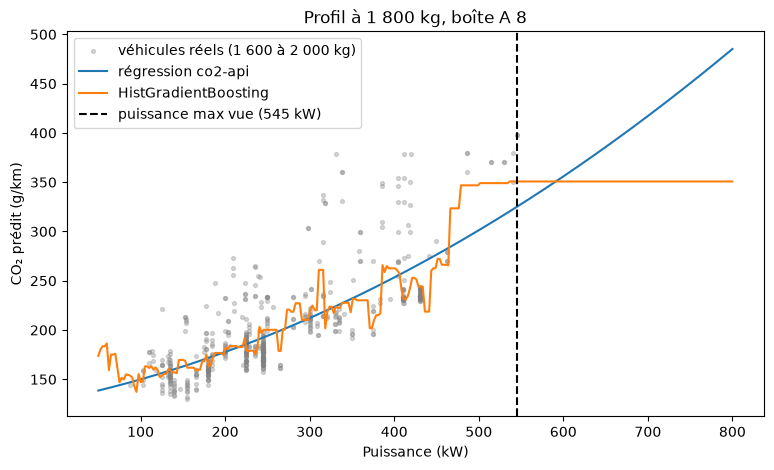

In [27]:
p_max = X_tr["puiss_max"].max()
puissances = np.linspace(50, 800, 300)
profil = pd.DataFrame(
    {
        "masse_ordma_min": 1800,
        "puiss_max": puissances,
        "typ_boite_nb_rapp": "A 8",
    }
)

modele_lin = construire_pipe_lineaire(LinearRegression()).fit(X_tr, y_tr)
modele_hgb = recherche_hgb.best_estimator_

proches = X_tr["masse_ordma_min"].between(1600, 2000)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(
    X_tr.loc[proches, "puiss_max"],
    y_tr[proches],
    s=8,
    alpha=0.3,
    color="grey",
    label="véhicules réels (1 600 à 2 000 kg)",
)
ax.plot(puissances, modele_lin.predict(profil), label="régression co2-api")
ax.plot(puissances, modele_hgb.predict(profil), label="HistGradientBoosting")
ax.axvline(
    p_max, color="black", linestyle="--", label=f"puissance max vue ({p_max:.0f} kW)"
)
ax.set_xlabel("Puissance (kW)")
ax.set_ylabel("CO₂ prédit (g/km)")
ax.set_title("Profil à 1 800 kg, boîte A 8")
ax.legend()
plt.show()

Dans le domaine des données, le boosting suit les véhicules réels en escalier. Au-delà de la puissance maximale vue à l’entraînement (ligne pointillée), sa prédiction devient plate : chaque arbre renvoie la valeur de sa dernière feuille. La régression prolonge sa courbe, sans que rien ne garantisse qu’elle reste plausible. Ni l’un ni l’autre n’est fiable hors du domaine d’entraînement.

## Partie 7 - Conclusion et choix de l'API

In [28]:
finalistes = {
    "régression co2-api": modele_lin,
    "HistGradientBoosting": modele_hgb,
}
pd.Series(
    {nom: mean_absolute_error(y_te, m.predict(X_te)) for nom, m in finalistes.items()},
    name="MAE test (g/km)",
).round(2)

régression co2-api      14.54
HistGradientBoosting     8.59
Name: MAE test (g/km), dtype: float64

**Résultat principal.** Avec les mêmes trois variables, le boosting réduit l’erreur de 16,1 à 10,6 g/km en validation croisée, et de 14,5 à 8,6 g/km sur le jeu de test, jamais utilisé pour choisir les modèles. Les deux modèles font un peu mieux sur le test, mais l’écart entre eux se maintient (environ 6 g/km). Sur le haut du parc, l’erreur passe de 29,2 à 16,1 g/km, et l’erreur relative y devient la même qu’ailleurs (environ 6 %). L’hypothèse du deuxième notebook est donc réfutée : l’excès d’erreur sur les véhicules puissants venait de la forme du modèle linéaire, pas de l’absence de la carrosserie et de l’aérodynamique. Ces variables pourraient en revanche expliquer une partie de l’erreur résiduelle d’environ 6 %, présente uniformément sur tout le parc.

**Limite.** Au-delà de la puissance maximale vue à l’entraînement, la prédiction du boosting devient plate, tandis que la régression prolonge sa courbe sans garantie de plausibilité. Aucun des deux n’est fiable hors du domaine. Pour l’API, je signalerai la sortie du domaine dans la réponse (un champ `dans_le_domaine`, sur le modèle de `boite_connue`), plutôt que de restreindre les bornes de `Vehicule` : l’utilisateur obtient une réponse et sait qu’elle est peu fiable.

**Choix pour l’API.** `HistGradientBoostingRegressor` (`max_iter=600`, `learning_rate=0.1`, `max_leaf_nodes=7`, `min_samples_leaf=3`). XGBoost fait jeu égal, mais HistGradientBoosting fait partie de scikit-learn : pas de dépendance supplémentaire, même sauvegarde `joblib`, et le pipeline reste compatible avec `api.py`. Le modèle déployé sera réentraîné sur l’ensemble des données.